# ODMR Notebook
You can use this notebook to do Optically Detected Magnetic Resonance (ODMR) measurements on the Room Temperature NV setup. The idea behind such a measurement is that you see the dependence of the emission rate of the NV center on the frequency of a microwave electric signal that is transmitted close to the NV center. To do this, the measurement controls two main instruments:
1. **The DAC**: The National Instruments (NI) Digital-to-Analog Converter (DAC) is used to readout the amount of photons emitted by the NV center. It is hooked up to the output of the Avalanche Photo Detectors and counts the number of detected photons within a specified time interval. By default, it runs on a 10Hz clock.
2. **The RF Source**: This instrument generates the microwave signal that is transmitted close to the NV center. Using the specified functions, you can change the frequency of the signal it outputs, as well as it's amplitude (in a log-scale unit: the dBm; see: https://en.wikipedia.org/wiki/DBm).

By controlling these two instruments, you will write an ODMR measurement in the code below. To help you get started, some functions are pre-defined:
1. `init_equipment()` prepares the DAC and RF source such that their functionalities become available. This function should be ran once, right after starting a `QMI environment`. The function outputs the DAC and RF source objects.
2. `set_microwave_frequency(rf_source, mw_frequency_hz)` a function with which you can change the microwave frequency that the RF source outputs. It's inputs are the RF source Python object and the desired microwave frequency in Hz.
3. `set_microwave_power(rf_source, mw_power_dbm)` a function with which you can change the microwave power that the RF sourc outputs. It's inputs are the RF source Python object and the desired microwave power in dBm.
4. `get_count_array(dac, nof_samples)` a function that outputs an array with length `nof_samples` containing the number of counted photons, expressed as *photons per second*.
5. `save_dataset(dataset, name)` a function that saves your xarray Dataset in the data folder with the specified name.
6. `load_dataset(name)` a function that loads a saved xarray Dataset from the data folder with the specified name.

In the cells below, we've setup a framework for you to write your own code in.

In [1]:
# Some required imports, please don't remove anything here. Feel free to add imports
import qmi
import os
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

from qmi.utils.context_managers import start_stop
from nodes.rt_practicum.RP.rp_utils import (
    init_equipment, 
    fit_two_peaks, 
    save_dataset, 
    load_dataset, 
    set_microwave_frequency, 
    set_microwave_power,
    get_count_array
)

os.environ["QMI_HOME"] = "C:\\Users\\TUD277232\\Repositories\\diamondos"

In [2]:
def odmr():
	with start_stop(qmi, "rt_practicum_odmr"):
		# Initialize QMI framework.
		dac, rfsource = init_equipment()

		# START WRITING CODE BELOW HERE!
		mw_freq = np.arange(2.75e9,3.2e9,1e6) #Hz
		mw_pow = 20  #dbm
		final_data = np.array([])
		for i in tqdm(mw_freq):
			set_microwave_frequency(rfsource, i)
			set_microwave_power(rfsource, mw_pow)
			data = get_count_array(dac, 50)
			data_avg = np.average(data)
			final_data = np.append(final_data, data_avg)


		# print(final_data)
		# For data saving purposes, we want you to use the library xarray. In this pre-written code, we make an xarray Dataset that contains all your data.
		# From your experiment, you should be able to get an [N,M] size array (here called "count_rate_array").
		# Here N is the size of the first dimension and represents the microwave frequencies
		# And M is the size of the second dimension and represents the repetitions at each microwave frequency.
		# From this array, we can calculate the average_count_rate array by integrating over the repetitions.
		dataset = xr.Dataset()
		dataset['mw_frequency'] = mw_freq # < A NUMPY ARRAY WITH ALL THE MW FREQUENCIES###
		dataset['repetitions'] = np.array([0,1,2,3,4])   ### < A NUMPY ARRAY LIKE [0, 1, 2, ..., ] AS AN INDEX OF THE NUMBER OF REPETITIONS
		dataset['photon_counts'] = xr.DataArray(final_data, dims=["mw_frequency"])#, "repetitions"])

		dac.close()

		return dataset

dataset = odmr(
	#ADD YOUR ARGUMENTS
)

2026-10-27 15:48:03.082 | INFO     | qmi.core.context_singleton | QMI starting (prog='c:\\Users\\TUD277232\\.virtualenvs\\diamondos-y5ebUVmr\\lib\\site-packages\\ipykernel_launcher.py', context='rt_practicum_odmr', pid=12268, config=None)
2026-10-27 15:48:03.084 | INFO     | qmi.core.context       | Starting QMI context 'rt_practicum_odmr'
2026-10-27 15:48:03.089 | INFO     | qmi.core.messaging     | Starting UDP responder on port 35999 ...
2026-10-27 15:48:03.092 | INFO     | qmi.core.context       | QMI context 'rt_practicum_odmr' now active
2026-10-27 15:48:03.268 | INFO     | qmi.instruments.rohde_schwarz.sgs100a | [rt_practicum_rfsource] Opening connection to instrument
2026-10-27 15:48:03.274 | INFO     | instruments.ni.usb_6361 | [rt_practicum_dac] Opening connection to instrument
2026-10-27 15:48:03.491 | INFO     | nodes.rt_practicum.control.equipment | Using National Instruments USB 6361 Data Acquisition Card.
100%|██████████| 450/450 [03:45<00:00,  2.00it/s]
2026-10-27 15:51

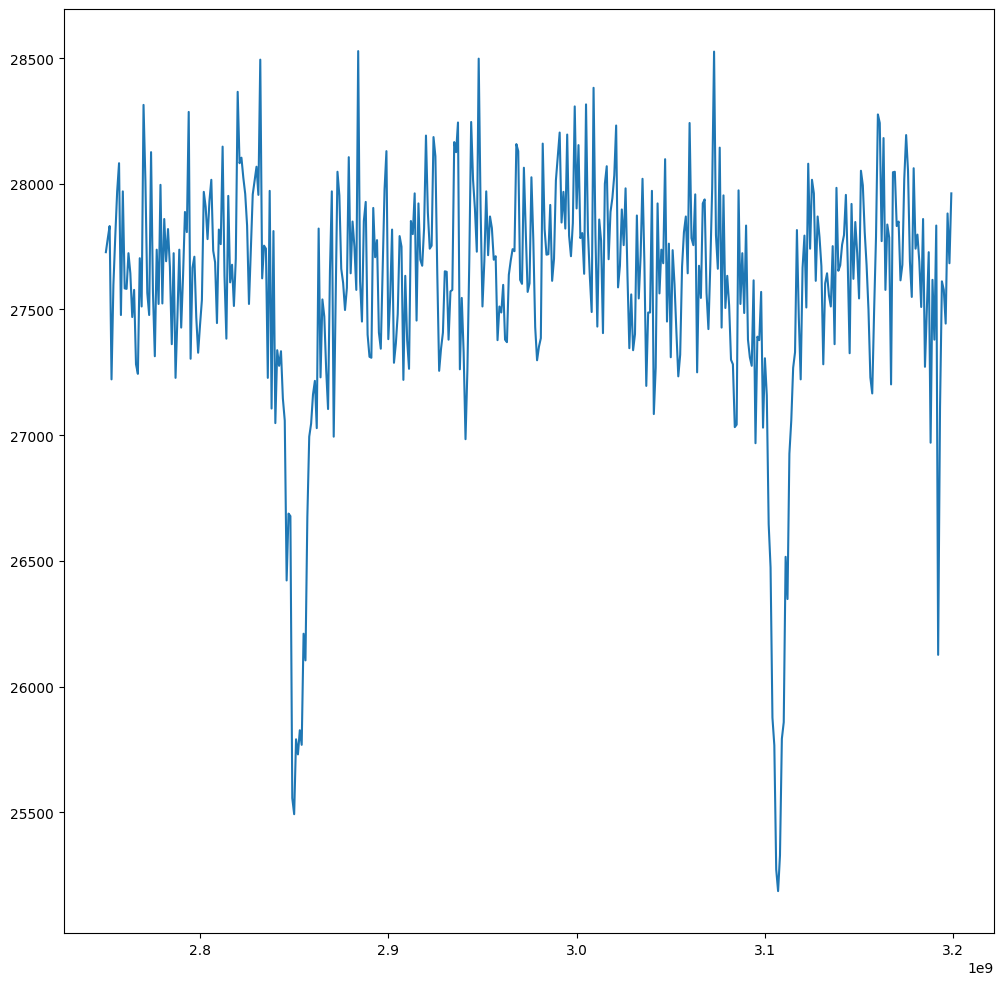

In [ ]:
save_dataset(dataset, "Set_Magneet_36rot")
#Aantal rotaties is bepaald door de magneet te verplaatsen vanaf het punt dat deze uit de ijzeren omhulsel komt richting de diamant 1 rotatie = 350 micrometer
#de afstand tussen de start en de chip is 2.35 +- 0.1cm 

plt.figure(figsize=(12, 12))
plt.plot(dataset["mw_frequency"], dataset["photon_counts"])

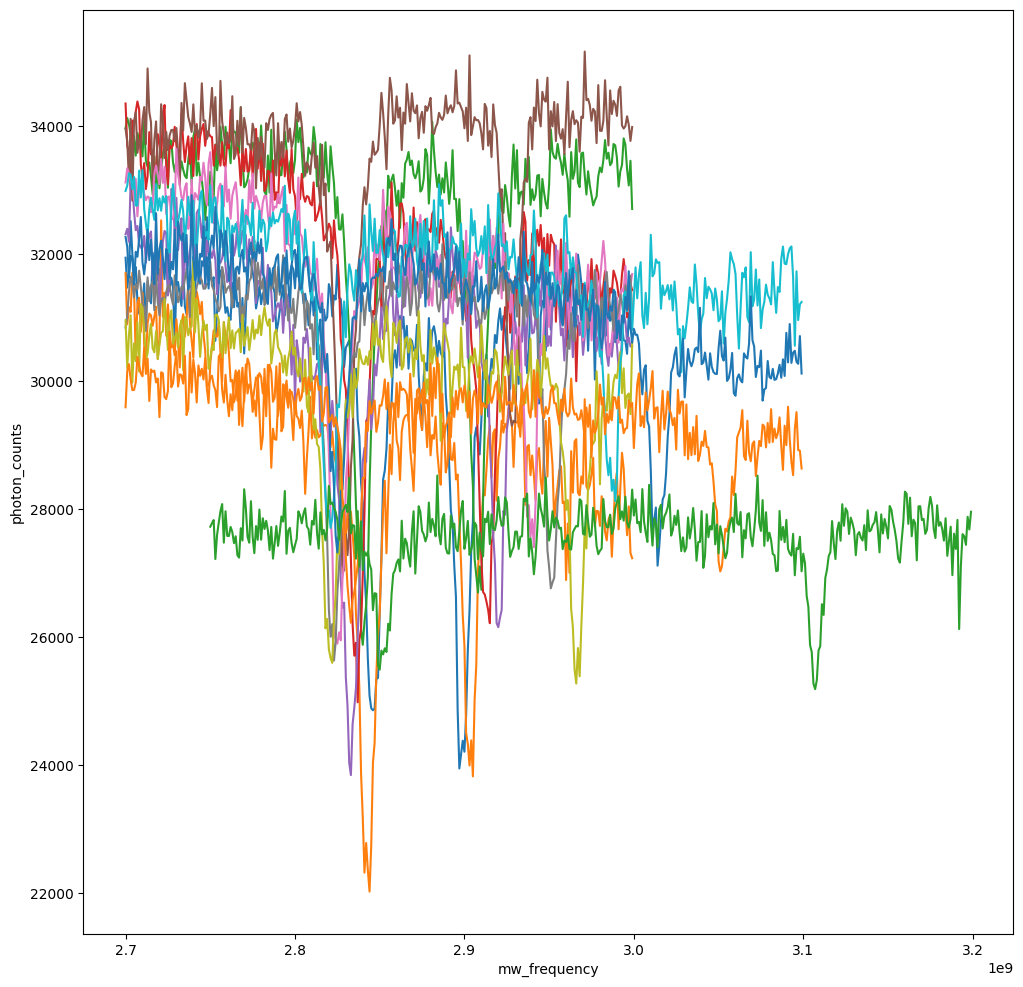

In [4]:
data = load_dataset("Set_Magneet_0rot")
plt.figure(figsize=(12, 12))
data.photon_counts.plot()
data2 = load_dataset("Set_Magneet_3rot")
data2.photon_counts.plot()
data3 = load_dataset("Set_Magneet_6rot")
data3.photon_counts.plot()
data4 = load_dataset("Set_Magneet_9rot")
data4.photon_counts.plot()
data5 = load_dataset("Set_Magneet_12rot")
data5.photon_counts.plot()
data6 = load_dataset("Set_Magneet_15rot")
data6.photon_counts.plot()
data7 = load_dataset("Set_Magneet_18rot")
data7.photon_counts.plot()
data8 = load_dataset("Set_Magneet_21rot")
data8.photon_counts.plot()
data9 = load_dataset("Set_Magneet_24rot")
data9.photon_counts.plot()
data10 = load_dataset("Set_Magneet_27rot")
data10.photon_counts.plot()
data11 = load_dataset("Set_Magneet_30rot")
data11.photon_counts.plot()
data12 = load_dataset("Set_Magneet_33rot")
data12.photon_counts.plot()
data13 = load_dataset("Set_Magneet_36rot")
data13.photon_counts.plot()